# Member 3 — Clustering Track: Agglomerative Hierarchical Clustering (Gas Sensor Array Drift)

**Review 2 scope (Member 3):** the **Agglomerative** half of clustering deliverable **B1** — fit the model and obtain
cluster labels with no errors. K-Means is in `clustering_member2.ipynb`; the Elbow curve, Dendrogram, linkage
comparison, all metrics (B2) and PCA / t-SNE plots (B3) are in `member1_clustering_evaluation.ipynb`.

- Same preprocessing and k as the K-Means notebook, so the two algorithms are compared on identical inputs.
- The gas label (`class`) and `concentration` are removed before fitting and used only in section 6.
- Labels are saved to `results/clustering/agglomerative_labels.csv`.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
warnings.filterwarnings('ignore', category=UserWarning)
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'

DATA_PATH = Path('../data/raw/gassensor/gas_sensor/gas_sensor.csv')
RESULTS_DIR = Path('../results/clustering')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Load and audit

In [2]:
df = pd.read_csv(DATA_PATH)
GAS_NAMES = {1: 'Ethanol', 2: 'Ethylene', 3: 'Ammonia', 4: 'Acetaldehyde', 5: 'Acetone', 6: 'Toluene'}

y_gas = df['class'].map(GAS_NAMES)                    # kept aside; never used for fitting
X_raw = df.drop(columns=['class', 'concentration'])   # explicit: the two label columns are removed by name

print('shape:', df.shape, '| clustering features:', X_raw.shape[1])
print('missing values:', int(X_raw.isna().sum().sum()), '| infinite values:', int(np.isinf(X_raw.values).sum()),
      '| duplicate rows:', int(df.duplicated().sum()))
print('constant features:', int((X_raw.nunique() <= 1).sum()))

shape: (13910, 130) | clustering features: 128
missing values: 0 | infinite values: 0 | duplicate rows: 0
constant features: 0


**Audit findings.** 13,910 measurements x 128 sensor features; no missing, infinite, duplicate or constant values, so
no imputation or column removal is needed. The label columns are dropped by name rather than guessed.

## 2. Preprocessing

1. **Signed log transform** `sign(x) * log1p(|x|)` — the features are heavily skewed and many are negative; this
   compresses the tails while keeping the sign.
2. **`StandardScaler`** — Ward linkage is defined on Euclidean distances, so every feature must be on the same scale.

Identical to the K-Means notebook (Member 2), so the two algorithms see the same matrix.

In [3]:
X_log = np.sign(X_raw) * np.log1p(X_raw.abs())
X = StandardScaler().fit_transform(X_log)
print('scaled matrix:', X.shape)
print('max |skewness| before: %.1f | after signed log: %.1f' % (X_raw.skew().abs().max(), X_log.skew().abs().max()))

scaled matrix: (13910, 128)


max |skewness| before: 117.9 | after signed log: 6.2


## 3. Agglomerative clustering — how it works and the settings used

- **Bottom-up:** every measurement starts as its own cluster; the two closest clusters are merged, again and again,
  until `n_clusters` remain. The full merge history is the dendrogram (B2 notebook).
- **Linkage = Ward:** merges the pair whose union increases the total within-cluster variance the least. The B2
  notebook compares ward, complete, average and single linkage on this data: average and single put 13,907 of the
  13,910 points in one cluster, complete leaves a 1-point cluster, and only Ward gives four usable clusters.
- **k = 4:** from the K-Means elbow curve (Member 2 / B2) and confirmed by the natural cut of the Ward dendrogram
  (B2). The gas count (6) is *not* used, because that would let the labels steer the fit.
- Merges are greedy and never undone, and the model has no `predict` for new points — it labels the data it was
  fitted on.

cluster sizes: [4782, 3365, 4271, 1492]


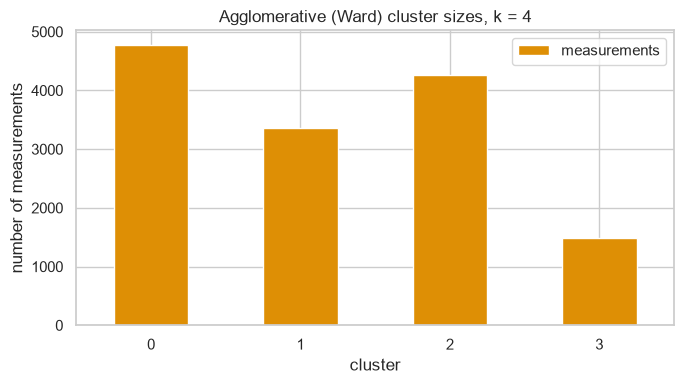

In [4]:
K = 4
agg = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X)
agg_labels = agg.labels_
sizes = pd.Series(agg_labels).value_counts().sort_index()
print('cluster sizes:', sizes.tolist())

ax = sizes.plot.bar(figsize=(7, 4), color=sns.color_palette('colorblind')[1], label='measurements')
ax.set_title(f'Agglomerative (Ward) cluster sizes, k = {K}')
ax.set_xlabel('cluster')
ax.set_ylabel('number of measurements')
ax.legend()
plt.xticks(rotation=0)
save_fig('m3_agg_cluster_sizes.png')
plt.show()

**Observation.** Sizes 4,782 / 3,365 / 4,271 / 1,492 (34% / 24% / 31% / 11%): four usable clusters, none tiny or
dominant. Ward tends to produce clusters of similar variance, and here it isolates one smaller, tighter group
(cluster 3).

### 3.1 Internal metrics (sanity check)

Computed on all 13,910 rows (no sampling). The full comparison with K-Means is in the B2 notebook.

In [5]:
quick = pd.Series({'silhouette': silhouette_score(X, agg_labels, random_state=RANDOM_STATE),
                   'davies_bouldin': davies_bouldin_score(X, agg_labels),
                   'calinski_harabasz': calinski_harabasz_score(X, agg_labels)}, name='Agglomerative (ward)')
display(quick.round(3).to_frame())

,Agglomerative (ward)
silhouette,0.202
davies_bouldin,1.378
calinski_harabasz,5390.260


**Observation.** Silhouette 0.202, Davies-Bouldin 1.378, Calinski-Harabasz 5,390 — moderately overlapping clusters.
These are the full-data values (an earlier version used a 5,000-row silhouette sample) and match the B2 notebook
exactly, because the preprocessing, k and linkage are the same.

## 4. Cluster profiles

Mean scaled value of each cluster on the 16 sensors' **steady-state resistance change** (features 1, 9, 17, ..., 121).

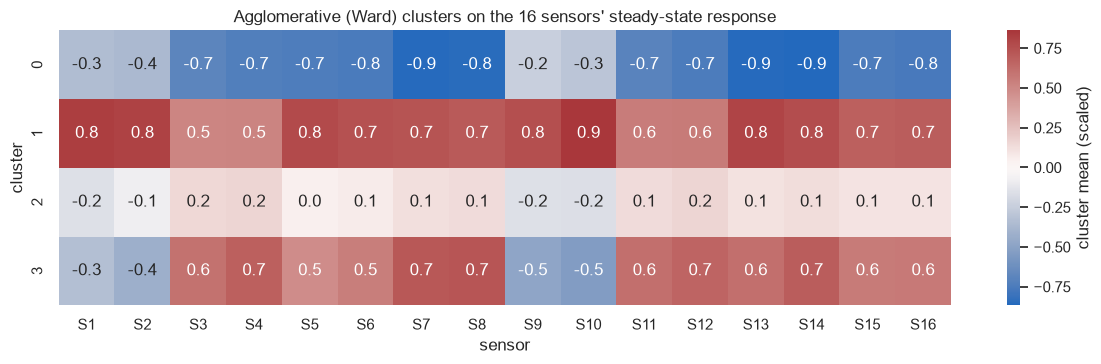

In [6]:
steady = [f'feature_{1 + 8 * s}' for s in range(16)]
idx = [X_raw.columns.get_loc(c) for c in steady]
profile = pd.DataFrame(X[:, idx], columns=[f'S{s + 1}' for s in range(16)]).groupby(agg_labels).mean()
profile.index.name = 'cluster'

plt.figure(figsize=(12, 3.8))
sns.heatmap(profile, cmap='vlag', center=0, annot=True, fmt='.1f', cbar_kws={'label': 'cluster mean (scaled)'})
plt.title('Agglomerative (Ward) clusters on the 16 sensors\' steady-state response')
plt.xlabel('sensor')
plt.ylabel('cluster')
save_fig('m3_agg_cluster_profile.png')
plt.show()

**Observation.** The clusters differ in **how strongly the sensors respond**:
- cluster 1: every sensor well above average (+0.5 to +0.9) — strong response;
- cluster 0: every sensor below average (-0.2 to -0.9) — weak response;
- cluster 3: a **sensor-specific pattern** — S1, S2, S9, S10 below average while the other 12 sensors are well above.
  A pattern like this points to one particular gas (section 6: Ethylene);
- cluster 2: close to average on every sensor — the "in-between" measurements.

## 5. Agreement with K-Means (Member 2)

Cluster numbers are arbitrary, so the two labellings are compared with a cross-tabulation and the Adjusted Rand
Index (1 = identical partitions, 0 = chance). Requires `clustering_member2.ipynb` to have been run.

In [7]:
km_path = RESULTS_DIR / 'kmeans_labels.csv'
km_labels = pd.read_csv(km_path)['kmeans_cluster'].to_numpy()
assert len(km_labels) == len(agg_labels), 'K-Means labels do not match this data set'
print('agreement between K-Means and Ward (ARI): %.3f' % adjusted_rand_score(km_labels, agg_labels))
display(pd.crosstab(pd.Series(km_labels, name='K-Means cluster'), pd.Series(agg_labels, name='Ward cluster')))

agreement between K-Means and Ward (ARI): 0.503


Ward cluster,0,1,2,3
K-Means cluster,,,,
0,1852,48,2753,0
1,0,3307,399,60
2,9,10,1035,1432
3,2921,0,84,0


**Observation.** ARI 0.50: moderate agreement. Both algorithms find the same strong-response group (K-Means 1 ≈
Ward 1, 3,307 shared measurements). Ward's cluster 3 (1,492) sits almost entirely inside K-Means cluster 2 (2,486) —
Ward keeps only the core of that group. The two disagree on the average-response measurements: K-Means cluster 0 is
split between Ward clusters 0 and 2. Ward's greedy merges cannot be undone, while K-Means keeps reassigning points,
so their boundaries differ in the dense middle of the data.

## 6. What the clusters contain (gas labels used only now)

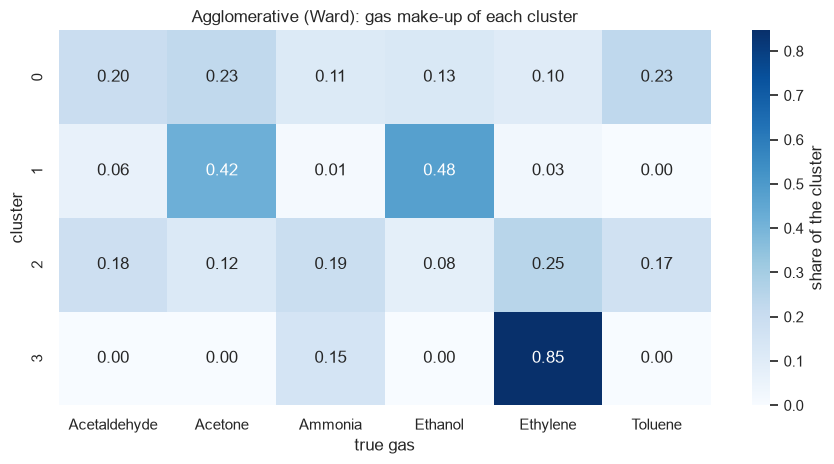

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.8))
ct = pd.crosstab(pd.Series(agg_labels, name='cluster'), y_gas.rename('gas'), normalize='index')
sns.heatmap(ct, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'share of the cluster'}, ax=ax)
ax.set_title('Agglomerative (Ward): gas make-up of each cluster')
ax.set_xlabel('true gas')
ax.set_ylabel('cluster')
save_fig('m3_agg_cluster_gas_makeup.png')
plt.show()

**Observation.**
- Cluster 3 is **85% Ethylene** — the sensor-specific pattern in section 4.
- Cluster 1 is **Acetone + Ethanol** (42% + 48% = 90%) — the strong-response group.
- Clusters 0 and 2 mix Acetaldehyde, Toluene, Ammonia and the rest; with 4 clusters for 6 gases and sensor drift
  over 36 months, a one-to-one match with the gases was not expected (external agreement is analysed in B2).

## 7. Save labels

In [9]:
out = pd.DataFrame({'agglomerative_cluster': agg_labels, 'gas': y_gas, 'concentration': df['concentration']})
out.to_csv(RESULTS_DIR / 'agglomerative_labels.csv', index_label='row')
print('saved:', RESULTS_DIR / 'agglomerative_labels.csv')
display(out.head())

saved: ../results/clustering/agglomerative_labels.csv


,agglomerative_cluster,gas,concentration
0,0,Ethanol,10.0
1,0,Ethanol,20.0
2,0,Ethanol,30.0
3,0,Ethanol,40.0
4,0,Ethanol,50.0


## 8. Summary (B1 — Agglomerative)

- **Agglomerative clustering fitted with no errors** on all 13,910 measurements x 128 signed-log, standardised
  features: Ward linkage, k = 4 (from the elbow / dendrogram, not from the gas labels).
- Sizes 4,782 / 3,365 / 4,271 / 1,492; silhouette 0.202, Davies-Bouldin 1.378, Calinski-Harabasz 5,390.
- Agrees moderately with K-Means (ARI 0.50); both find an Ethylene cluster and an Acetone + Ethanol cluster.
- Saved: `results/clustering/agglomerative_labels.csv`, used by the B2/B3 notebook
  (`member1_clustering_evaluation.ipynb`).